# 교양교과목록 학년도별 편성/트렌드 분석 (TF-IDF 제외)
- 파일 경로만 수정하고 위에서 아래로 실행
- 그래프 한글 깨짐/워드클라우드 오류 방지 포함

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from matplotlib import font_manager, rc
import warnings
warnings.filterwarnings("ignore")

# ===== 한글 폰트 설정 (Windows: 맑은고딕) =====
_font_path = "C:/Windows/Fonts/malgun.ttf"
try:
    _font_name = font_manager.FontProperties(fname=_font_path).get_name()
    rc('font', family=_font_name)
    plt.rcParams['axes.unicode_minus'] = False
    print("폰트 적용:", _font_name)
except Exception as e:
    print("폰트 적용 실패:", e)
# ============================================


폰트 적용: Malgun Gothic


In [4]:
# TODO: 로컬 실행 시 엑셀 경로만 수정
excel_path = r"data/[수정본]교양교과목록_최종.xlsx"  # 예시: 로컬에서는 C:/... 로 변경

df = pd.read_excel(excel_path)

# 기본 전처리
df['학년도'] = df['학년도'].astype(int)
df['이수구분'] = df['이수구분'].astype(str)
df['교과목명'] = df['교과목명'].astype(str)
df['교과설명'] = df['교과설명'].fillna("").astype(str)

df.head()


,학년도,학기 / 보류,교과목명,교과설명,이수구분,수강기준학년,수강기준학기
0,2025,1,자연재해의이해,"자연재해와 관련하여 엘리뇨, 지구온난화, 태풍, 홍수, 가뭄, 수질오염, 산사태, ...",교선,0,0
1,2025,1,사회봉사활동,"현장에 직접 나가 봉사활동을 실시하며, 활동영역으로는 캠퍼스, 농어촌, 공공기관, ...",교필,0,0
2,2025,1,세계의민족과문화,이 강좌는 문화인류학 연구 성과에 기반하여 각 민족과 그들의 문화를 이해하는 것을 ...,교선,0,0
3,2025,1,교양음악,음악에 대한 기초적인 지식을 배우며 음악감상 등을 통해 음악에 대해 쉽게 접근을 할...,교선,0,0
4,2025,1,자동차와생활,현대적인 생활에 있어서 자동차는 누구나 쉽게 보유하고 운전하게 됨으로서 이제는 자동...,교선,0,0


In [5]:
# 학년도별 개설 과목 수
year_count = df.groupby('학년도')['교과목명'].count().sort_index()
year_count


학년도
2022     44
2023     34
2024     85
2025    165
Name: 교과목명, dtype: int64

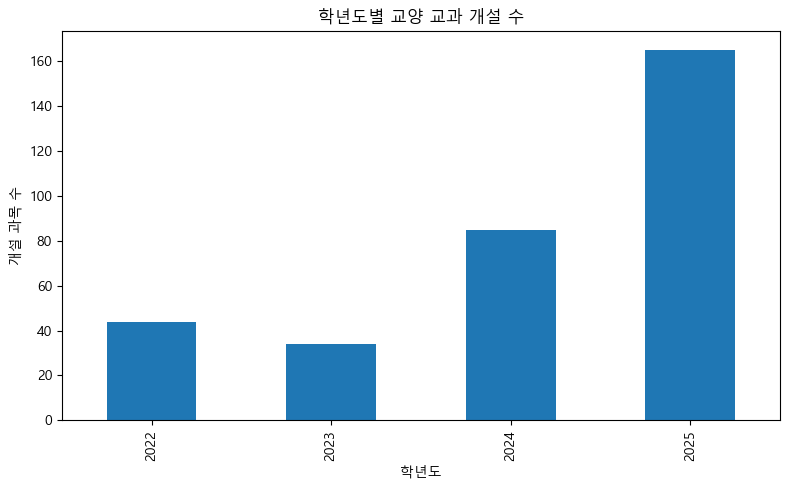

In [6]:
plt.figure(figsize=(8,5))
year_count.plot(kind='bar')
plt.title("학년도별 교양 교과 개설 수")
plt.xlabel("학년도")
plt.ylabel("개설 과목 수")
plt.tight_layout()
plt.show()


In [7]:
# 학년도 x 이수구분 개설 수
year_type = df.groupby(['학년도','이수구분']).size().unstack(fill_value=0).sort_index()
year_type


이수구분,교선,교필,자선,전선,채플
학년도,,,,,
2022,28,12,3,1,0
2023,14,19,1,0,0
2024,43,31,10,1,0
2025,87,63,14,0,1


In [8]:
# 연도별 이수구분 비율
year_type_ratio = year_type.div(year_type.sum(axis=1), axis=0)
year_type_ratio


이수구분,교선,교필,자선,전선,채플
학년도,,,,,
2022,0.636364,0.272727,0.068182,0.022727,0.000000
2023,0.411765,0.558824,0.029412,0.000000,0.000000
2024,0.505882,0.364706,0.117647,0.011765,0.000000
2025,0.527273,0.381818,0.084848,0.000000,0.006061


<Figure size 1200x600 with 0 Axes>

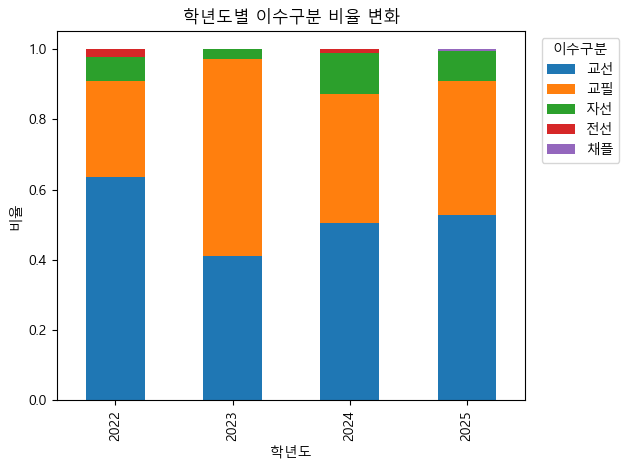

In [9]:
plt.figure(figsize=(12,6))
year_type_ratio.plot(kind='bar', stacked=True)
plt.title("학년도별 이수구분 비율 변화")
plt.xlabel("학년도")
plt.ylabel("비율")
plt.legend(title="이수구분", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


=== 2022년 워드클라우드 ===


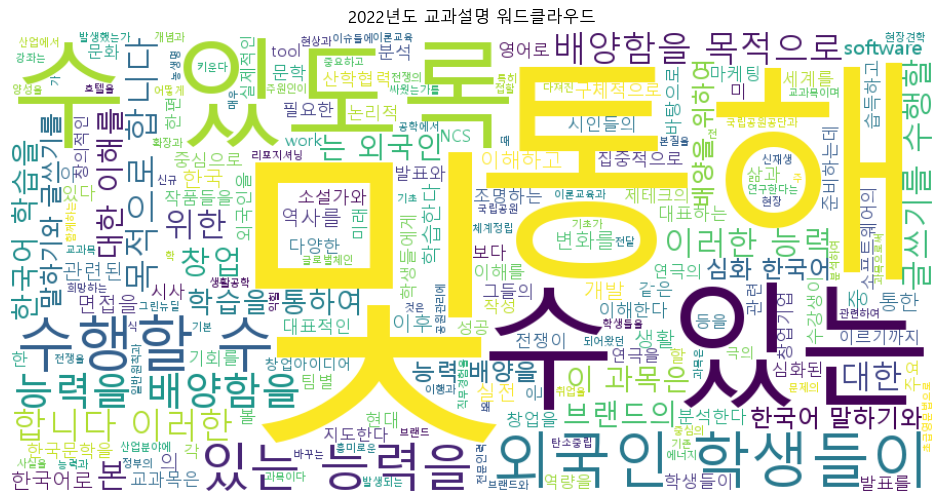

=== 2023년 워드클라우드 ===


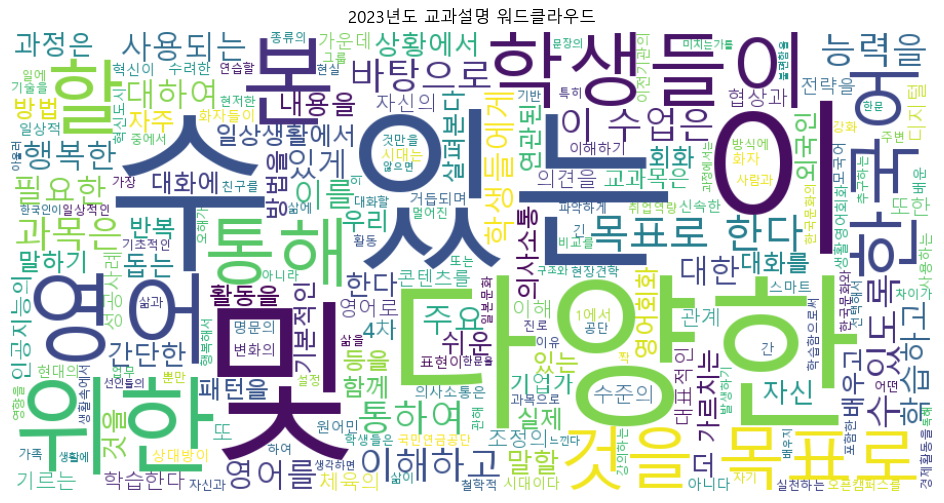

=== 2024년 워드클라우드 ===


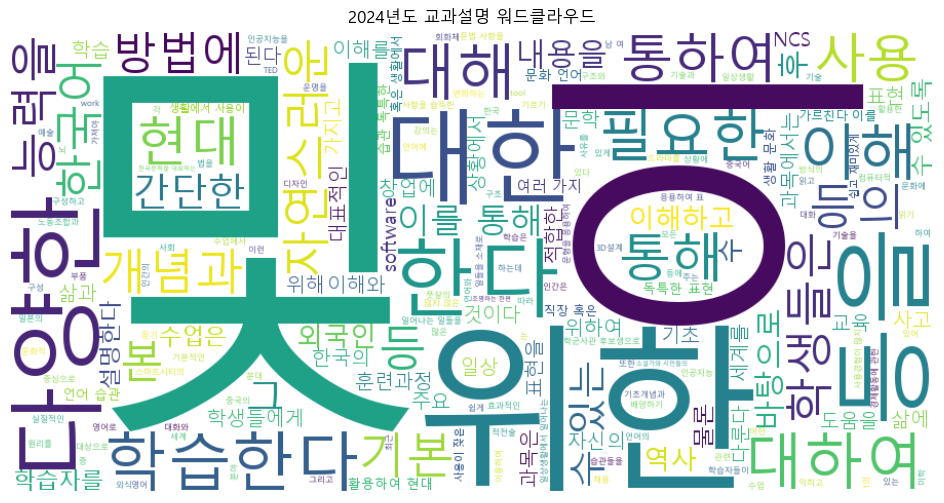

=== 2025년 워드클라우드 ===


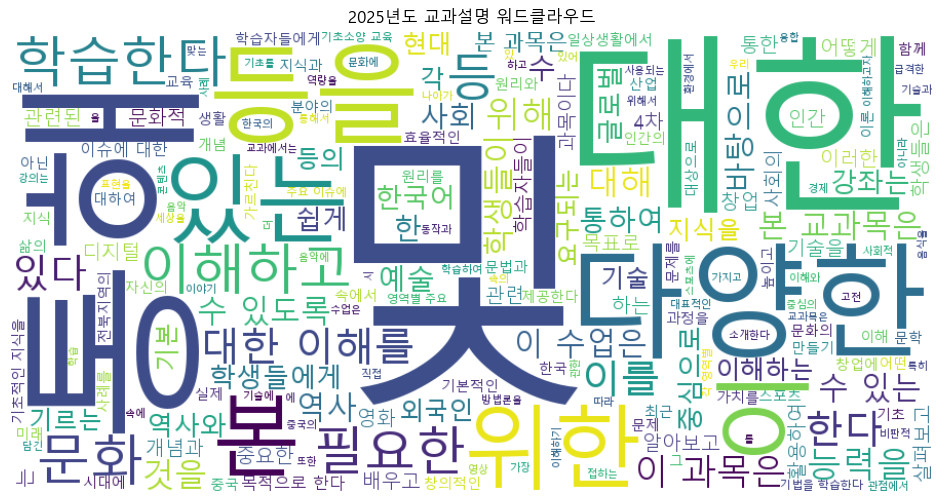

In [10]:
# 학년도별 워드클라우드 (교과설명 기반)
for year in sorted(df['학년도'].unique()):
    texts = df.loc[df['학년도']==year, '교과설명'].tolist()
    text = " ".join([t for t in texts if isinstance(t, str)]).strip()
    print(f"=== {year}년 워드클라우드 ===")

    if not text:
        print("텍스트 없음 -> 스킵\n")
        continue

    wc = WordCloud(
        width=900,
        height=450,
        background_color='white',
        font_path=_font_path  # 한글 폰트 필수
    ).generate(text)

    plt.figure(figsize=(12,6))
    plt.imshow(wc, interpolation='bilinear')
    plt.axis('off')
    plt.title(f"{year}년도 교과설명 워드클라우드")
    plt.show()


In [11]:
# 연도별 신규/폐지 교과 탐지
years = sorted(df['학년도'].unique())
new_courses = {}
deleted_courses = {}

for i in range(1, len(years)):
    prev_year = years[i-1]
    curr_year = years[i]

    prev = set(df.loc[df['학년도']==prev_year, '교과목명'])
    curr = set(df.loc[df['학년도']==curr_year, '교과목명'])

    new_courses[curr_year] = sorted(list(curr - prev))
    deleted_courses[curr_year] = sorted(list(prev - curr))

print("=== 연도별 신규 교과 ===")
for y, lst in new_courses.items():
    print(f"{y}년 신규 {len(lst)}개")
    print(lst[:50], "\n")  # 너무 길면 앞 50개만

print("=== 연도별 폐지 교과 ===")
for y, lst in deleted_courses.items():
    print(f"{y}년 폐지 {len(lst)}개")
    print(lst[:50], "\n")


=== 연도별 신규 교과 ===
2023년 신규 34개
['경제자료의이해', '글로벌잉글리시', '기독교와문화', '기본영어회화(1)', '기본영어회화(2)', '디지털미디어와영어', '사례를통해서배우는갈등해결의지혜', '생활속분쟁의해결방법', '생활영어회화(1)', '생활영어회화(2)', '소셜웰빙', '실용영어회화(1)', '실용영어회화(2)', '알기쉬운인공지능', '연기금의이해', '영어회화(1)', '영어회화(2)', '외국인을위한대학작문', '외국인을위한프리젠테이션', '외국인을위한한국문학산책', '운동과건강', '음료로보는현대사회의이해', '일본문화의이해', '적성이이끄는삶', '정의란무엇인가', '중급한문', '지도와지리학으로읽는제2차세계대전사', '지속가능한농업', '지역기업의이해', '창업과리더십', '한국문학으로읽는여행', '한국문학의이해와감상', '한국어(1)', '환경과인간'] 

2024년 신규 84개
['3D모델링및3D프린팅실무', 'ChatGPT프로젝트', 'K-MOOC', 'NCS이해와진로설계', 'NCS취업실전', 'TED로배우는영어', 'TOPIK한국어', '경제의개념과활용', '글로벌잉글리시Ⅱ', '글로벌패션문화', '금융생활과소비자', '기본일본어회화(2)', '기본중국어회화(2)', '기업경영과노사관계', '기초군사훈련', '기초일본어표현', '기초중국어표현', '내삶이보이는동양철학', '뇌과학과창의력개발', '뉴스로배우는한국어', '대학생습관형성과공부방법', '데이터분석기초', '드라마로배우는한국어', '디자인과창의성', '멀티캠퍼스채용연계풀스택개발자양성과정', '미국탐방시리즈', '미디어로배우는영어', '미래사회와스마트팩토리', '반려동물의이해', '배드민턴', '법의이해', '보험과사회', '사람과세상을이해하는고전문학읽기', '사례를통해배우는갈등해결의지혜', '사진촬영과감상법', '생활속의경제', '서양고대철학', '소프트웨어적사고', '시스템다이내믹스를이용한문제해결', '실용일본어회화(2)', '실용중국어회화(2)